In [1]:
import pandas as pd

# XLS from https://www.pnas.org/doi/10.1073/pnas.1913050117#supplementary-materials
# converted to Open data format
df = pd.read_excel("pnas.1913050117.sd01.ods", engine="odf")

print(df.head())
print(df.shape)
#print(df.dtypes)

regions = df["region"].unique()
regions.sort()
print(f"Num regions: {len(regions)}")
print(regions)

# 15 states

unique_pairs = df[["region", "state"]].drop_duplicates()

# should be 15 -- Surveys were conducted in 15 of 37 Nigerian states in 2016 and 2017 by eHealth Africa (Fig. 1). 
print(f"States {len(unique_pairs)}")
print(unique_pairs)

# A -- settlement area
# t -- settlement type
#  settled area within a 1-km radius (𝑥4), 
# residential area in a 1-km radius (𝑥5), 
# and nonresidential settled area within a 1-km radius (𝑥6)
# We scaled the WorldPop Global estimates (𝑥1) based on their mean and SD nationally. 
# We calculated school densities (𝑥2) within a 1-km radius of each 100-m grid cell.
# We mapped household sizes (𝑥3) at 100 m resolution nationally by interpolating

print( df["type"].unique() )



     N         A  type  region  state  local         x1         x2        x3  \
0  547  3.036998     1       2      1      4   2.197421   8.676227  0.355697   
1  803  2.989821     1       2      1     10   1.762664  11.563097  0.518146   
2  750  3.078278     1       2      1     12   4.382428   6.422414  1.299024   
3  281  3.019307     1       2      1     17  12.165173  11.681791  1.217722   
4  730  3.025204     1       2      1      4   1.886113   9.077245  0.616274   

          x4         x5        x6  
0   6.103109   5.937570  4.729498  
1   4.519900   6.797936  2.849132  
2  10.277397  12.096138  9.851146  
3  15.145932  15.937444  6.920267  
4   8.900904   9.391248  3.409727  
(1141, 12)
Num regions: 11
[ 1  2  3  4  5  6  7  8  9 10 11]
States 15
      region  state
0          2      1
102        1      1
203        9      1
207        2      2
246        5      1
345        6      1
446        3      1
546        8      1
642        9      2
723       10      1
765        

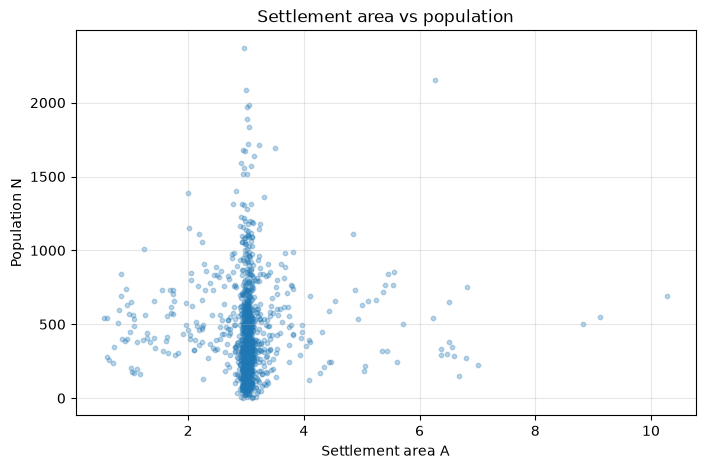

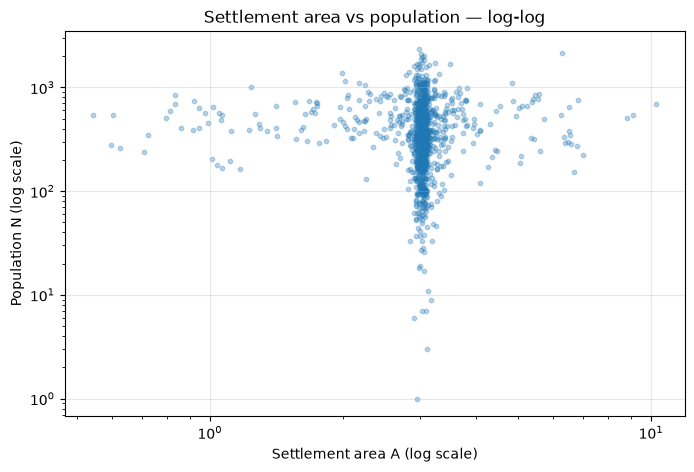

In [2]:
# Plotting Area vs N to see relationship, if its linear or not

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.scatter(df["A"], df["N"], alpha=0.3, s=10)
plt.xlabel("Settlement area A")
plt.ylabel("Population N")
plt.title("Settlement area vs population")
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(8, 5))
plt.scatter(df["A"], df["N"], alpha=0.3, s=10)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Settlement area A (log scale)")
plt.ylabel("Population N (log scale)")
plt.title("Settlement area vs population — log-log")
plt.grid(True, alpha=0.3)
plt.show()

In [3]:
# very basic model where we estimate just a global population density
import pymc as pm
import worldpop 
from importlib import reload

reload(worldpop)

    
area = df["A"].to_numpy()
N = df["N"].to_numpy()

from numpy.random import default_rng
rng = default_rng(42)

with pm.Model() as model_1:

    # Population density prior:
    # D ~ LogNormal(mu_log_D, sigma_log_D)
    #
    # LaTeX:
    # $ \log D \sim \mathcal{N}(\mu_{\log D}, \sigma_{\log D}^2) $
    #
    # D is strictly positive. The parameters describe log-density,
    # not density directly.
    D = pm.LogNormal(
        "D",
        mu=0,
        sigma=2,
    )

    # Population count likelihood:
    # N_i ~ Poisson(D * A_i)
    # i -- survey cluster
    # $ N_i \sim \operatorname{Poisson}(D A_i) $
    #
    #
    # D = population density
    # A_i = settlement area
    # D * A_i = expected population count
    #
    # This assumes the same density D for all observations.
    N_obs = pm.Poisson(
        "N_obs",
        mu=D * area,
        observed=N,
    )

    idata_1 = worldpop.sample_or_load(
        lambda: pm.sample(
            draws=2000,
            tune=2000,
            chains=4,
            random_seed=rng,
            #target_accept=0.95,
        ),
        "./idata_1.trace",
    )

import arviz as az
az.summary(idata_1, var_names=["D"], ci_prob=0.95, ci_kind="hdi")


/home/eric/stats/.venv/lib/python3.14/site-packages/arviz/__init__.py:110: MigrationWarning: arviz.InferenceData is no longer available on the arviz package; ArviZ now uses xarray's DataTree for the same role. See the migration guide: https://python.arviz.org/en/latest/user_guide/migration_guide.html#datatree
  warnings.warn(


,mean,sd,hdi95_lb,hdi95_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
D,146.151,0.207,150,150,3367,4702,1.00,0.0036,0.0022


In [4]:
# Posterior mean of the shared density D
D_mean = idata_1.posterior["D"].mean().item()

# Expected population for each cluster
N_pred = D_mean * area

# Compare observed and predicted populations
comparison = pd.DataFrame({
    "N_observed": N,
    "N_predicted": N_pred,
    "residual": N - N_pred,
})

comparison

# print(comparison["residual"].sum())


,N_observed,N_predicted,residual
0,547,443.860057,103.139943
1,803,436.965144,366.034856
2,750,449.893107,300.106893
3,281,441.274465,-160.274465
4,730,442.136329,287.863671
...,...,...,...
1136,364,347.331268,16.668732
1137,547,430.070230,116.929770
1138,332,498.157501,-166.157501
1139,705,517.118513,187.881487


In [5]:


import numpy as np
import pandas as pd
from scipy.stats import pearsonr

# Posterior mean of the shared population density D.
# D_draws contains samples from the posterior distribution of D.
# Posterior mean of the shared density D
D_mean = idata_1.posterior["D"].mean().item()

# Expected population for each cluster:
# E[N_i | D, A_i] = D * A_i
# Average over posterior draws to account for uncertainty in D.

# Expected population for each cluster
N_pred = D_mean * area

import worldpop 
from importlib import reload
reload(worldpop)

metrics = worldpop.score_metrics(df, N_pred)

print(D_mean)

metrics


146.15092296573212


/home/eric/stats/.venv/lib/python3.14/site-packages/arviz/__init__.py:110: MigrationWarning: arviz.InferenceData is no longer available on the arviz package; ArviZ now uses xarray's DataTree for the same role. See the migration guide: https://python.arviz.org/en/latest/user_guide/migration_guide.html#datatree
  warnings.warn(


Bias (people)                 -0.008860
Imprecision (people)         332.328484
Inaccuracy / MAE (people)    246.633641
R²                             0.000194
Scaled bias                   -0.082118
Scaled imprecision             0.889957
Scaled inaccuracy              0.604712
Name: Value, dtype: float64

In [ ]:
# now we add density per local and state

# $ \mu_{region} \sim N$ 

reload(worldpop)
worldpop.prepare_hierachy_indices(df)

n_regions = len(df["region_idx"].unique())
n_states = len(df["state_idx"].unique())
n_locals = len(df["local_idx"].unique())

print(f"Number regions {n_regions} states {n_states} locales {n_locals} min {df['region_idx'].min()}")

state_idx = df["state_idx"].to_numpy()
region_idx = df["region_idx"].to_numpy()
local_idx = df["local_idx"].to_numpy()

# One parent region index for each unique state.
state_parent_region_idx = (
    df[["state_idx", "region_idx"]]
    .drop_duplicates("state_idx")
    .sort_values("state_idx")["region_idx"]
    .to_numpy(dtype=int)
)

assert len(state_parent_region_idx) == n_states

assert np.array_equal(
    state_parent_region_idx[df["state_idx"].to_numpy()],
    df["region_idx"].to_numpy(),
)

local_parent_state_idx = (
    df[["local_idx", "state_idx"]]
    .drop_duplicates("local_idx")
    .sort_values("local_idx")["state_idx"]
    .to_numpy(dtype=int)
)

assert len(local_parent_state_idx) == n_locals

assert np.array_equal(
    local_parent_state_idx[df["local_idx"].to_numpy()],
    df["state_idx"].to_numpy(),
)


with pm.Model() as model_hierarchical:
    # Standard deviations at each hierarchical level:
    # $\sigma_{\text{region}} \sim \operatorname{HalfNormal}(1)$
    # $\sigma_{\text{state}} \sim \operatorname{HalfNormal}(1)$
    # $\sigma_{\text{local}} \sim \operatorname{HalfNormal}(1)$
    sigma_region = pm.HalfNormal("sigma_region", sigma=1)
    sigma_state = pm.HalfNormal("sigma_state", sigma=1)
    sigma_local = pm.HalfNormal("sigma_local", sigma=1)

    # Region-level mean log-density:
    # $\mu_{\text{region}} \sim    \mathcal{N}(\mu, \sigma_{\text{region}})$

    # Global mean log-density:
    # $\mu_{global} \sim \mathcal{N}(0, 2^2)$
    # use the naive model above to start it out
    mu_global = pm.Normal("mu_global", mu=np.log(150), sigma=2)

    # use a non-centered parameterization
    # so instead of $ \mu_{region} \sim N(\mu_{global}, \sigma_{region}) $
    # where $ \sigma_{region} $ could be small 
    # mu_region = pm.Normal(
    #     "mu_region",
    #     mu=mu_global,
    #     sigma=sigma_region,
    #     shape=n_regions,
    # )
    mu_region_raw = pm.Normal(
        "mu_region_raw", mu=0, sigma=1, shape=n_regions
    )
    # $ \mu_{global} + \sigma_{region} \mu_{region\_raw} $
    mu_region = pm.Deterministic(
        "mu_region",
        mu_global + sigma_region * mu_region_raw
    )

    # State-level mean log-density, conditional on its parent region:
    # State-level mean log-density:
    # $\mu_{\text{state}[s]} = \mu_{\text{region}[r[s]]} + \sigma_{\text{state}} \mu_{mu\_state\_raw[s]}$
    mu_state_raw = pm.Normal(
        "mu_state_raw", mu=0, sigma=1, shape=n_states
    )
    mu_state = pm.Deterministic(
        "mu_state",
        mu_region[state_parent_region_idx]
        + sigma_state * mu_state_raw,
    )

    # Local-level mean log-density, conditional on its parent state:
    mu_local_raw = pm.Normal(
        "mu_local_raw", mu=0, sigma=1, shape=n_locals
    )
    
    mu_local = pm.Deterministic(
        "mu_local",
        mu_state[local_parent_state_idx]
        + sigma_local * mu_local_raw,
    )

    # Density for each observation:
    # $\log D_i = \mu_{\text{local}[l]}$
    # $D_i = \exp(\mu_{\text{local}[l]})$
    D = pm.Deterministic(
        "D",
        pm.math.exp(mu_local[local_idx]),
    )

    # Population count likelihood:
    # $N_i \sim \operatorname{Poisson}(D_i A_i)$
    N_obs = pm.Poisson(
        "N_obs",
        mu=D * area,
        observed=N,
    )

    idata_hierarchical = worldpop.sample_or_load(
        lambda: pm.sample(
            draws=2000,
            tune=2000,
            chains=4,
            random_seed=rng,
            max_treedepth=15,
            target_accept=0.99,
        ),
        "./idata_hierarchical.trace",
        clean=False
    )

# begin
# this is just to show any continous parameter spits out a density function
# whose integral / sum area == 1
import numpy as np
from scipy.stats import gaussian_kde
from scipy.integrate import trapezoid

samples = (
    idata_hierarchical
    .posterior["sigma_local"]
    .values
    .flatten()
)

kde = gaussian_kde(samples)

x = np.linspace(0, samples.max() * 1.2, 10000)
density = kde(x)

print("KDE area:", trapezoid(density, x))
# end 

# Posterior mean log-density and corresponding density by region.
print("Regions:")
print(
    idata_hierarchical.posterior["mu_region"]
    .mean(dim=("chain", "draw"))
    .to_dataframe(name="mean_log_density")
    .assign(mean_density=lambda x: np.exp(x["mean_log_density"]))
)

# Posterior mean log-density and corresponding density by state.
print("Expected number of states:", n_states)

# Model variable shape
print("mu_state shape:", mu_state.eval().shape)

print(f"States: ")
print(
    "Posterior states:",
    idata_hierarchical.posterior["mu_state"].sizes["mu_state_dim_0"],
)
print(
    idata_hierarchical.posterior["mu_state"]
    .mean(dim=("chain", "draw"))
    .to_dataframe(name="mean_log_density")
    .assign(mean_density=lambda x: np.exp(x["mean_log_density"]))
)

print("what")
for name, idata in [
    ("Centered", idata_hierarchical),
    ("Non-centered", idata_hierarchical),
]:
    divs = idata.sample_stats["diverging"].sum().values
    print(f"{name}: {divs} divergences")

summary = az.summary(
    idata_hierarchical,
    var_names=[
        "mu_global",
        "sigma_region",
        "sigma_state",
        "sigma_local",
        "mu_region_raw",
        "mu_state_raw",
        "mu_local_raw",
    ],
)

#print(summary[["mean", "sd", "ess_bulk", "ess_tail", "r_hat"]])

print(
    summary.sort_values("r_hat", ascending=False)
    [["mean", "sd", "ess_bulk", "ess_tail", "r_hat"]]
    .head(20)
)

az.summary(
    idata_hierarchical,
    var_names=[
        "sigma_region",
        "sigma_state",
        "sigma_local",
        "mu_global",
    ],
)




/home/eric/stats/.venv/lib/python3.14/site-packages/arviz/__init__.py:110: MigrationWarning: arviz.InferenceData is no longer available on the arviz package; ArviZ now uses xarray's DataTree for the same role. See the migration guide: https://python.arviz.org/en/latest/user_guide/migration_guide.html#datatree
  warnings.warn(


Number regions 11 states 15 locales 232 min 0
KDE area: 0.9999999999999984
Regions:
                 mean_log_density  mean_density
mu_region_dim_0                                
0                        4.865978    129.797793
1                        4.880385    131.681415
2                        5.183521    178.309513
3                        5.089541    162.315390
4                        5.020442    151.478276
5                        4.637926    103.329841
6                        5.015222    150.689560
7                        4.975955    144.887077
8                        4.942897    140.175684
9                        4.838733    126.309195
10                       4.996667    147.919290
Expected number of states: 15
mu_state shape: (15,)
States: 
Posterior states: 15
                mean_log_density  mean_density
mu_state_dim_0                                
0                       4.763085    117.106645
1                       4.819654    123.922194
2                     

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
sigma_region,0.225,0.114,0.046,0.41,3113,4237,1.00,0.002,0.0015
sigma_state,0.188,0.095,0.049,0.35,1731,2213,1.00,0.0022,0.0012
sigma_local,0.4639,0.0225,0.43,0.5,2783,3323,1.00,0.00043,0.00025
mu_global,4.95,0.105,4.8,5.1,7924,5434,1.00,0.0012,0.0014


Number of regions: 11


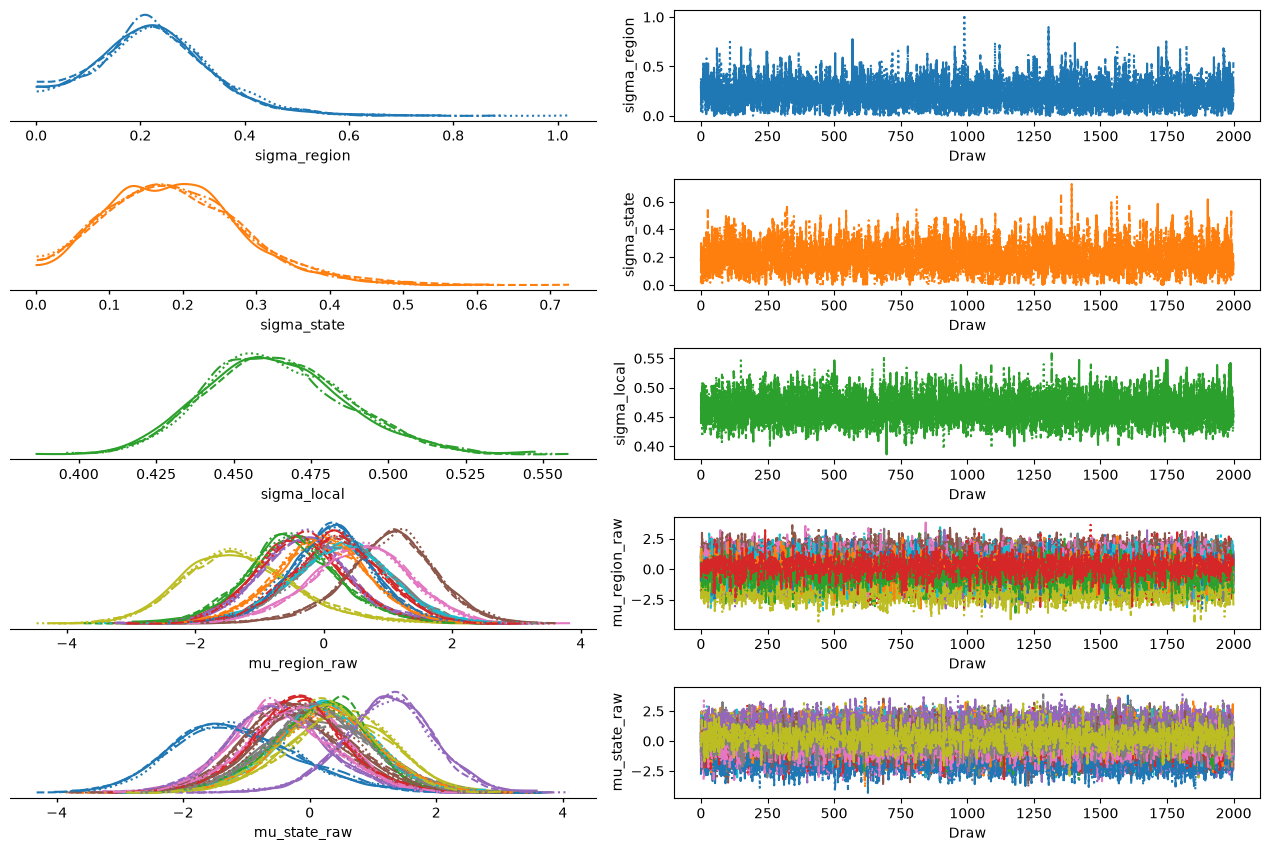

In [7]:
import arviz_plots as azp

azp.plot_trace_dist(
    idata_hierarchical,
    var_names=["sigma_region", "sigma_state", "sigma_local", "mu_region_raw",
            "mu_state_raw",],
     backend="matplotlib",
)
print("Number of regions:", n_regions)

plt.tight_layout()
plt.show()

In [8]:

counts = pd.Series(local_idx).value_counts().reindex(
    range(n_locals), fill_value=0
)

print(counts.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]))
print("\nObservations per local area:")
print(counts.value_counts().sort_index().to_string())

print("\nLocal areas with 0 observations:", (counts == 0).sum())
print("Local areas with 1 observation:", (counts == 1).sum())
print("Local areas with <= 5 observations:", (counts <= 5).sum())
print("Total observations:", counts.sum())

count    232.000000
mean       4.918103
std        6.270747
min        1.000000
10%        1.000000
25%        2.000000
50%        3.000000
75%        6.000000
90%       10.000000
max       58.000000
Name: count, dtype: float64

Observations per local area:
count
1     49
2     43
3     37
4     26
5     16
6     12
7     11
8      6
9      7
10     3
11     2
12     5
13     1
14     2
15     3
17     3
18     1
23     1
26     1
29     1
48     1
58     1

Local areas with 0 observations: 0
Local areas with 1 observation: 49
Local areas with <= 5 observations: 171
Total observations: 1141


In [9]:
import pandas as pd
import numpy as np

df_density = pd.DataFrame({
    "region": region_idx,
    "state": state_idx,
    "local": local_idx,
    "population": N,
    "area": area,
})

df_density["density"] = df_density["population"] / df_density["area"]

def grouped_density(df, level):
    result = (
        df.groupby(level)
        .agg(
            population=("population", "sum"),
            area=("area", "sum"),
            n_observations=("population", "size"),
        )
    )
    result["avg_density"] = result["population"] / result["area"]
    return result.sort_values("avg_density", ascending=False)

region_density = grouped_density(df_density, "region")
state_density = grouped_density(df_density, "state")
local_density = grouped_density(df_density, "local")

print("\n=== Density by region ===")
print(region_density.to_string())

print("\n=== Density by state ===")
print(state_density.to_string())

print("\n=== Density by local area ===")
print(local_density.to_string())


=== Density by region ===
        population        area  n_observations  avg_density
region                                                     
2           117987  624.229872             209   189.012102
4            56202  307.839550             101   182.569134
3            50288  301.806834              99   166.623132
6            48437  291.581291              96   166.118340
8            48319  321.597446             106   150.246840
10           19567  130.767826              43   149.631608
7            37433  261.205414              81   143.308668
0            37317  316.437498             103   117.928502
9            34208  309.390483             102   110.565780
1            32301  304.867420             101   105.950974
5            25646  304.047726             100    84.348600

=== Density by state ===
       population        area  n_observations  avg_density
state                                                     
10          48809  210.720483              86   2

In [10]:

# Posterior draws of density for each observation
D_samples = idata_hierarchical.posterior["D"].values
# Shape: (chains, draws, n_observations)

# Expected population per observation
pop_samples = D_samples * area

print(len(pop_samples))


# Posterior mean population estimate
estimated_pop = pop_samples.mean(axis=(0, 1))

print("Estimated population:")
print(estimated_pop)

print("Shape:", estimated_pop.shape)

metrics = worldpop.score_metrics(df, estimated_pop)

# These are close to https://pmc.ncbi.nlm.nih.gov/articles/PMC7533662/table/t03/

metrics

4
Estimated population:
[436.32776295 475.91205402 662.00363815 ... 541.58311045 562.19700047
 470.85011041]
Shape: (1141,)


Bias (people)                 -0.000255
Imprecision (people)         257.141414
Inaccuracy / MAE (people)    181.012626
R²                             0.352187
Scaled bias                   -0.030719
Scaled imprecision             0.604473
Scaled inaccuracy              0.434855
Name: Value, dtype: float64